<table>
<tr>
<td width="190" align="center" valign="top">
<img src="https://raw.githubusercontent.com/gustavomartinellidev/ai-governance-lab/main/assets/profile.png" width="140" style="border-radius:50%;" alt="Gustavo Martinelli"><br>
<b>Gustavo Martinelli</b><br>
<sub>AI Engineer &amp; AI Governance Specialist</sub><br><br>
<a href="https://www.linkedin.com/in/gustavomartinelli/" target="_blank">🔗 Connect on LinkedIn</a>
</td>
<td valign="top">

# 🧠 Inside a Neural Network: One Decision, Layer by Layer

### An explainability walkthrough from an AI governance perspective

👋 **Welcome!** In this notebook we train a small neural network, ask it to make **one decision**, and then open it up to see **why** it decided that way, layer by layer and neuron by neuron.

The goal is not only to build a model, but to show what **explaining an automated decision** can look like. That question sits at the heart of AI governance.

▶️ **How to use:** `Runtime → Run all`. It takes about a minute, needs no GPU, and produces an **animated GIF** and a plain-language **explainability report** at the end.

</td>
</tr>
</table>

## 📣 About This Post

> *This notebook accompanies my LinkedIn post. Here is the full text:*

**Can we explain why an AI made a decision?**

This animation shows a small neural network, trained on the classic Iris dataset, making one prediction layer by layer:

- 🟠 **Orange**: the signals that actually flowed through the network
- ⚪ **Gray**: neurons that stayed inactive for this input (ReLU output = 0)
- 🔵 **Blue**: the decision path, the route that pushed hardest toward the final answer
- 📊 The output layer turns everything into probabilities

For a model with 12 neurons, we can literally trace the decision. For models with billions of parameters, we can't, and that is exactly where AI governance gets hard.

Regulations such as Brazil's **LGPD (Art. 20)** and the **EU AI Act (Art. 86)** give people the right to understand automated decisions that affect them. Visualizations like this are a starting point. Real accountability also needs rigorous attribution methods, documentation and human review.

Understanding what happens inside the model is where explainability begins.

#AIGovernance #ExplainableAI #XAI #LGPD #AIAct #ResponsibleAI #MachineLearning

## 🗺️ Roadmap

Each section answers a question an auditor, a DPO or a regulator could ask about an AI system.

| Section | What we do | Governance question |
|---|---|---|
| 1. Setup | Load libraries, fix random seeds | *Can the result be reproduced?* |
| 2. The Data | Load and prepare the Iris dataset | *What was the model trained on?* |
| 3. The Model | Define a 4 → 5 → 3 neural network | *What exactly is the system?* |
| 4. Training | Train and evaluate the model | *How well does it perform? Which version is it?* |
| 5. Opening the Black Box | Record activations and trace the decision | *Why did it decide this?* |
| 6. Explainability Report | Write a plain-language report | *Can a non-technical reviewer understand it?* |
| 7. Visualizing the Decision | Animate the decision path | *Can we communicate it clearly?* |

## 1. ⚙️ Setup

### 1.1 Libraries and reproducibility

Every library used here comes preinstalled in Google Colab, so there is nothing to install.

We also fix the **random seeds**, which means the same code produces the same model and the same explanation on every run.

> 🏛️ **Governance note:** Reproducibility is a prerequisite for any audit. If an explanation cannot be reproduced, it cannot be verified.

In [1]:
import io
import random
import hashlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

AUTHOR = "Gustavo Martinelli"

print(f"PyTorch {torch.__version__} | NumPy {np.__version__} | seed = {SEED}")

PyTorch 2.11.0+cpu | NumPy 2.1.3 | seed = 42


## 2. 🌸 The Data

### 2.1 The Iris dataset

The Iris dataset (R. A. Fisher, 1936) is a classic in machine learning. It has **150 flowers** from **3 species** (*Setosa*, *Versicolor* and *Virginica*), each described by **4 measurements** in centimeters:

| Feature | Description |
|---|---|
| Sepal length | Length of the sepal, the green leaf-like part under the petals |
| Sepal width | Width of the sepal |
| Petal length | Length of the petal |
| Petal width | Width of the petal |

It ships with scikit-learn, so **no download is needed**.

> 🏛️ **Governance note:** Knowing where the data comes from, what it contains and what it does *not* contain is the first step of transparency. Every explanation is only as good as the data behind the model.

In [2]:
iris = load_iris()
FEATURES = ["Sepal length", "Sepal width", "Petal length", "Petal width"]
CLASSES = [name.capitalize() for name in iris.target_names]

df = pd.DataFrame(iris.data, columns=[f"{f} (cm)" for f in FEATURES])
df["Species"] = [CLASSES[t] for t in iris.target]

print(f"{len(df)} samples · {len(FEATURES)} features · {len(CLASSES)} classes\n")
display(df.sample(5, random_state=SEED))
df["Species"].value_counts()

150 samples · 4 features · 3 classes



,Sepal length (cm),Sepal width (cm),Petal length (cm),Petal width (cm),Species
73,6.1,2.8,4.7,1.2,Versicolor
18,5.7,3.8,1.7,0.3,Setosa
118,7.7,2.6,6.9,2.3,Virginica
78,6.0,2.9,4.5,1.5,Versicolor
76,6.8,2.8,4.8,1.4,Versicolor


,count
Species,
Setosa,50
Versicolor,50
Virginica,50


### 2.2 Preparing the data

Two steps:

1. **Train/test split (80% / 20%)**: the model learns from 120 flowers and is evaluated on 30 it has never seen. The split is *stratified*, so each species keeps the same proportion in both sets.
2. **Standardization**: each measurement is rescaled to mean 0 and standard deviation 1, which helps the network train. The scaler is fitted **only on the training data**, so no information leaks from the test set.

> 🏛️ **Governance note:** Because of standardization, the influences we measure later are relative to the **average flower in the training data**. Every explanation has a baseline, and a good report states it.

In [3]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, stratify=iris.target, random_state=SEED
)

scaler = StandardScaler().fit(X_train_raw)

X_train = torch.tensor(scaler.transform(X_train_raw), dtype=torch.float32)
X_test = torch.tensor(scaler.transform(X_test_raw), dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print(f"Training set: {len(X_train)} flowers | Test set: {len(X_test)} flowers")

Training set: 120 flowers | Test set: 30 flowers


## 3. 🏗️ The Model

### 3.1 Architecture

A small fully connected neural network, also called a *multilayer perceptron* (MLP):

| Layer | Neurons | Role |
|---|---|---|
| **Input layer** | 4 | Receives the 4 flower measurements |
| **Hidden layer** | 5 | Combines the measurements; uses **ReLU** activation |
| **Output layer** | 3 | One score per species; **Softmax** turns scores into probabilities |

- **ReLU** keeps positive signals and turns negative ones into **0**. A neuron that outputs 0 is *inactive* for that input and passes nothing forward.
- **Softmax** converts the three output scores into probabilities that add up to 100%.

> 🏛️ **Governance note:** This model is deliberately tiny, with 43 parameters, so that every single neuron can be inspected. Modern language models have **billions** of parameters, which is why explaining them requires very different tools.

In [4]:
class IrisNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 5)   # input layer  -> hidden layer
        self.relu = nn.ReLU()           # activation: negative signals become 0
        self.output = nn.Linear(5, 3)   # hidden layer -> output layer

    def forward(self, x):
        return self.output(self.relu(self.hidden(x)))  # raw scores (logits)


model = IrisNet()
n_params = sum(p.numel() for p in model.parameters())

print(model)
print(f"\nTrainable parameters: {n_params}")

IrisNet(
  (hidden): Linear(in_features=4, out_features=5, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=5, out_features=3, bias=True)
)

Trainable parameters: 43


## 4. 🏋️ Training

### 4.1 Training and evaluation

The model learns by repeatedly comparing its predictions with the correct species and adjusting its weights to reduce the error (**cross-entropy loss**, **Adam** optimizer, 300 passes over the data).

We then measure **accuracy on the 30 test flowers** the model has never seen.

> 🏛️ **Governance note:** Performance must be measured on held-out data and documented. Accuracy alone is not enough, though: a model can be right for the wrong reasons, which is why we look *inside* it in Section 5.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(1, 301):
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(X_train), y_train)
    loss.backward()
    optimizer.step()
    if epoch % 50 == 0:
        print(f"Epoch {epoch:3d} | loss {loss.item():.4f}")

model.eval()
with torch.no_grad():
    test_acc = (model(X_test).argmax(dim=1) == y_test).float().mean().item()

print(f"\nTest accuracy: {test_acc:.1%}")

Epoch  50 | loss 0.0504
Epoch 100 | loss 0.0399
Epoch 150 | loss 0.0349
Epoch 200 | loss 0.0310
Epoch 250 | loss 0.0290
Epoch 300 | loss 0.0252

Test accuracy: 93.3%


### 4.2 Model fingerprint

We compute a **SHA-256 hash of the model's weights**. It works like an ID card for this exact version of the model: retraining, or changing a single weight, produces a different fingerprint.

> 🏛️ **Governance note:** An explanation is only valid for the model version that produced it. Recording the fingerprint ties every decision, and its explanation, to a specific version, which is essential for audit trails.
>
> *The fingerprint may differ between machines or PyTorch versions, because floating-point results can vary slightly across hardware.*

In [6]:
weights_bytes = b"".join(p.detach().numpy().tobytes() for p in model.parameters())
MODEL_FINGERPRINT = hashlib.sha256(weights_bytes).hexdigest()[:16]

print(f"Model fingerprint (SHA-256, first 16 characters): {MODEL_FINGERPRINT}")

Model fingerprint (SHA-256, first 16 characters): 3374373282b6e320


## 5. 🔍 Opening the Black Box

### 5.1 Choosing the decision to explain

By default, we pick the **correctly classified** test flower on which the model was **least confident**.

Borderline decisions are the ones most likely to be questioned. In the real world they could be a credit application near the threshold, a transaction flagged as suspicious, or a candidate ranked just below the cut.

The model also makes mistakes. This cell lists the test flowers it got **wrong**, and explaining one of them is a great exercise (see Section 10). Set `SAMPLE_INDEX` to any number from 0 to 29 to explain a different flower.

In [7]:
SAMPLE_INDEX = None   # None = least-confident correct decision; or choose a number from 0 to 29

with torch.no_grad():
    test_probs = torch.softmax(model(X_test), dim=1)

correct = (test_probs.argmax(dim=1) == y_test).numpy()
wrong_cases = np.where(~correct)[0].tolist()

if SAMPLE_INDEX is None:
    confidence = test_probs.max(dim=1).values.numpy().copy()
    confidence[~correct] = np.inf          # skip misclassified flowers
    SAMPLE_INDEX = int(confidence.argmin())

x_raw = X_test_raw[SAMPLE_INDEX]
x = X_test[SAMPLE_INDEX : SAMPLE_INDEX + 1]
y_true = int(y_test[SAMPLE_INDEX])

print(f"Case #{SAMPLE_INDEX} | actual species: {CLASSES[y_true]}\n")
for name, value in zip(FEATURES, x_raw):
    print(f"  {name:<13} {value:.1f} cm")
print(f"\nMisclassified test flowers you can also explore: {wrong_cases or 'none'}")

Case #1 | actual species: Virginica

  Sepal length  6.1 cm
  Sepal width   3.0 cm
  Petal length  4.9 cm
  Petal width   1.8 cm

Misclassified test flowers you can also explore: [19, 25]


### 5.2 Recording internal activations with hooks

PyTorch **forward hooks** let us record what each layer produces **without changing the model**. They work like a flight recorder attached to the network.

We record:
- the hidden layer **after ReLU**, to see which neurons are active;
- the **output scores**, which become probabilities.

> 🏛️ **Governance note:** Hooks are a form of *non-intrusive instrumentation*. The system being audited is exactly the system in use, with nothing modified to make it explainable.

In [8]:
activations = {}

def record(name):
    def hook(module, inputs, output):
        activations[name] = output.detach().squeeze(0).numpy()
    return hook

handles = [
    model.relu.register_forward_hook(record("hidden")),
    model.output.register_forward_hook(record("logits")),
]

with torch.no_grad():
    logits = model(x)

for handle in handles:
    handle.remove()   # detach the recorders: the model is left untouched

probs = torch.softmax(logits, dim=1).squeeze(0).numpy()
pred = int(probs.argmax())

print("Hidden layer (after ReLU):")
for i, a in enumerate(activations["hidden"]):
    status = "active" if a > 0 else "inactive (ReLU = 0)"
    print(f"  H{i + 1}: {a:6.3f}  {status}")

print("\nOutput probabilities:")
for c, p in zip(CLASSES, probs):
    marker = "  ← prediction" if c == CLASSES[pred] else ""
    print(f"  {c:<11} {p:6.1%}{marker}")

Hidden layer (after ReLU):
  H1:  2.054  active
  H2:  0.000  inactive (ReLU = 0)
  H3:  2.967  active
  H4:  3.862  active
  H5:  1.710  active

Output probabilities:
  Setosa        0.0%
  Versicolor   25.7%
  Virginica    74.3%  ← prediction


### 5.3 Tracing the decision path

Each connection carries a **contribution = weight × signal**. From these contributions we derive three things:

| Concept | Meaning | Shown as |
|---|---|---|
| **Active signals** | The strongest contributions flowing through *active* neurons | 🟠 Orange |
| **Decision path** | The single route *input → hidden → output* that pushed hardest toward the prediction | 🔵 Blue |
| **Feature influence** | How much each measurement moved the predicted species' score | Report (Section 6) |

**Why the feature influence is exact:** a ReLU network behaves *linearly* for a given input once we know which neurons are active. So the predicted class score can be split exactly into one contribution per feature. This is the *gradient × input* method.

> ⚠️ **Honest caveat:** A dense network has **no single path**. Every active neuron contributes to the result. The "decision path" is a simplification that highlights what mattered most, not the whole computation.

In [9]:
W1 = model.hidden.weight.detach().numpy()   # shape (5, 4): input  -> hidden
W2 = model.output.weight.detach().numpy()   # shape (3, 5): hidden -> output
xs = x.squeeze(0).numpy()                   # standardized input
h = activations["hidden"]                   # hidden activations after ReLU
live = h > 0                                # which hidden neurons are active

# Contribution of each connection = weight × signal it carries
C1 = W1 * xs[None, :] * live[:, None]       # input -> hidden (inactive neurons pass nothing on)
C2 = W2 * h[None, :]                        # hidden -> output

# Decision path: the strongest positive push toward the predicted class
path_hidden = int(np.argmax(np.where(live, C2[pred], -np.inf)))
path_input = int(np.argmax(C1[path_hidden]))
PATH = (path_input, path_hidden, pred)

# Exact per-feature influence on the predicted class score (gradient × input)
feature_influence = ((W2[pred] * live) @ W1) * xs
share = np.abs(feature_influence) / np.abs(feature_influence).sum()

print(f"Decision path: {FEATURES[path_input]} → H{path_hidden + 1} → {CLASSES[pred]}\n")
print("Feature influence on the predicted class:")
for j in np.argsort(-share):
    direction = "supports" if feature_influence[j] > 0 else "opposes"
    print(f"  {FEATURES[j]:<13} {share[j]:6.1%}  ({direction} the prediction)")

Decision path: Petal length → H5 → Virginica

Feature influence on the predicted class:
  Petal length   47.5%  (supports the prediction)
  Petal width    45.8%  (supports the prediction)
  Sepal length    4.5%  (supports the prediction)
  Sepal width     2.2%  (supports the prediction)


## 6. 📋 Explainability Report

### 6.1 A report a non-technical reviewer can read

Neuron activations mean little to a lawyer, a DPO or the person affected by a decision. Here we translate everything above into a **plain-language report**, which is also saved as `explainability_report.txt`.

It contains:
- **Identification**: model version (fingerprint), date and case
- **Decision**: prediction, confidence and alternatives
- **Main reasons**: which features influenced the decision, and in which direction
- **Internal path**: the dominant route and the inactive neurons
- **Method and limitations**: how the explanation was produced and what it does *not* cover

> 🏛️ **Governance note:** Brazil's **LGPD (Art. 20, §1)** requires the controller to provide *clear and adequate information about the criteria and procedures* used in automated decisions. The **EU AI Act (Art. 86)** gives a *right to explanation* for decisions by high-risk systems, and the **GDPR (Art. 22)** protects people from solely automated decisions. A report like this is one practical building block toward those obligations, though not a complete solution on its own.

In [10]:
now = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
ranking = np.argsort(-share)
inactive = [f"H{i + 1}" for i in np.where(~live)[0]]
alternatives = ", ".join(f"{c} {p:.1%}" for k, (c, p) in enumerate(zip(CLASSES, probs)) if k != pred)

lines = [
    "AUTOMATED DECISION - EXPLAINABILITY REPORT",
    "=" * 56,
    f"Generated:          {now}",
    f"Model:              IrisNet (4-5-3 MLP), {n_params} parameters",
    f"Model fingerprint:  {MODEL_FINGERPRINT}",
    f"Test accuracy:      {test_acc:.1%}",
    f"Case analysed:      test sample #{SAMPLE_INDEX}",
    "",
    "1. INPUT",
    *[f"   - {name}: {value:.1f} cm" for name, value in zip(FEATURES, x_raw)],
    "",
    "2. DECISION",
    f"   Predicted:    {CLASSES[pred]} (confidence {probs[pred]:.1%})",
    f"   Actual:       {CLASSES[y_true]} -> {'CORRECT' if pred == y_true else 'INCORRECT'}",
    f"   Alternatives: {alternatives}",
    "",
    "3. MAIN REASONS (influence on the predicted class)",
    "   'supports' = pushed toward this species; 'opposes' = pushed away.",
    "   The rest of the decision comes from the model's learned starting point.",
    *[
        f"   {rank + 1}. {FEATURES[j]}: {share[j]:.0%}, "
        f"{'supports' if feature_influence[j] > 0 else 'opposes'} the decision"
        for rank, j in enumerate(ranking)
    ],
    "",
    "4. INTERNAL DECISION PATH",
    f"   {FEATURES[path_input]} -> hidden neuron H{path_hidden + 1} -> {CLASSES[pred]}",
    f"   Inactive neurons for this case: {', '.join(inactive) or 'none'}",
    "",
    "5. METHOD AND LIMITATIONS",
    "   - Influence = exact gradient x input decomposition for this input,",
    "     measured relative to the average flower in the training data.",
    "   - The decision path highlights the strongest route; every active",
    "     neuron contributes to the final result.",
    "   - This explains one decision only, not the model's overall behaviour.",
    "   - Human review is recommended before relying on this decision.",
]
report = "\n".join(lines)
print(report)

with open("explainability_report.txt", "w", encoding="utf-8") as f:
    f.write(report)

AUTOMATED DECISION - EXPLAINABILITY REPORT
Generated:          2026-10-14 15:23 UTC
Model:              IrisNet (4-5-3 MLP), 43 parameters
Model fingerprint:  3374373282b6e320
Test accuracy:      93.3%
Case analysed:      test sample #1

1. INPUT
   - Sepal length: 6.1 cm
   - Sepal width: 3.0 cm
   - Petal length: 4.9 cm
   - Petal width: 1.8 cm

2. DECISION
   Predicted:    Virginica (confidence 74.3%)
   Actual:       Virginica -> CORRECT
   Alternatives: Setosa 0.0%, Versicolor 25.7%

3. MAIN REASONS (influence on the predicted class)
   'supports' = pushed toward this species; 'opposes' = pushed away.
   The rest of the decision comes from the model's learned starting point.
   1. Petal length: 48%, supports the decision
   2. Petal width: 46%, supports the decision
   3. Sepal length: 4%, supports the decision
   4. Sepal width: 2%, supports the decision

4. INTERNAL DECISION PATH
   Petal length -> hidden neuron H5 -> Virginica
   Inactive neurons for this case: H2

5. METHOD AN

## 7. 🎬 Visualizing the Decision

### 7.1 Visual language

| Element | Meaning |
|---|---|
| ⚪ Hollow gray circle | A neuron before the signal reaches it |
| 🟠 Orange-filled circle | An active neuron; darker means a stronger value or activation |
| ⚪ Light gray filled circle | An **inactive** hidden neuron (ReLU output = 0) |
| 🟠 Orange line | An active signal; thicker means a larger contribution |
| 🔵 Blue line and border | The **decision path** |
| Light gray line | A connection that exists but carried little or no signal |

The animation plays the decision in steps: **inputs → hidden layer → output layer → decision path**.

> 🏛️ **Governance note:** Explainability is also a **communication** problem. The same explanation must reach engineers, managers, regulators and the affected person, each in a form they can understand.

### 7.2 Drawing function

This cell defines how **one frame** of the animation is drawn. Each frame is identified by a `stage` (which step of the decision is shown) and `t` (progress of a line being drawn, from 0 to 1).

In [11]:
# ---------- Visual style ----------
ORANGE, BLUE = "#e8590c", "#1c7ed6"
GRAY_EDGE, GRAY_NODE, DEAD_FILL, DEAD_EDGE = "#dee2e6", "#adb5bd", "#f1f3f5", "#ced4da"
TEXT, SUBTEXT = "#212529", "#868e96"

LAYER_SIZES = [4, 5, 3]
X_POS = [0.0, 4.0, 8.0]
Y_GAP = 1.15

STEP_CAPTIONS = {
    0: "A trained network, waiting for an input",
    1: "Step 1 · The flower's measurements enter the input layer",
    2: "Step 2 · Signals travel to the hidden layer (weight × value)",
    3: "Step 3 · ReLU: some neurons activate, others stay inactive",
    4: "Step 4 · Active neurons send their signals to the output layer",
    5: "Step 5 · Softmax turns the scores into probabilities",
    6: "Step 6 · Tracing the route that mattered most",
}


def node_xy(layer, i):
    n = LAYER_SIZES[layer]
    return X_POS[layer], ((n - 1) / 2 - i) * Y_GAP


def tint(color_hex, strength):
    """Blend from white to `color_hex` according to strength (0 to 1)."""
    c = np.array(matplotlib.colors.to_rgb(color_hex))
    s = 0.12 + 0.88 * float(np.clip(strength, 0, 1))
    return tuple(1 - (1 - c) * s)


def strong_edges(C, quantile=0.5):
    """Connections whose contribution is in the top half of non-zero contributions."""
    mag = np.abs(C)
    nonzero = mag[mag > 0]
    threshold = np.quantile(nonzero, quantile) if nonzero.size else np.inf
    return [
        (i, j, mag[i, j] / mag.max())
        for i in range(C.shape[0])
        for j in range(C.shape[1])
        if mag[i, j] > 0 and mag[i, j] >= threshold
    ]


def segment(ax, p0, p1, frac, color, lw, alpha=1.0, z=2):
    """Draw a line from p0 toward p1, covering `frac` of its length."""
    (x0, y0), (x1, y1) = p0, p1
    ax.plot([x0, x0 + (x1 - x0) * frac], [y0, y0 + (y1 - y0) * frac],
            color=color, lw=lw, alpha=alpha, solid_capstyle="round", zorder=z)


# Node fill intensities and highlighted connections for this decision
STRENGTH = [
    np.abs(xs) / np.abs(xs).max(),
    h / h.max() if h.max() > 0 else h,
    probs / probs.max(),
]
EDGES_1 = strong_edges(C1)   # (hidden i, input j, strength)
EDGES_2 = strong_edges(C2)   # (output i, hidden j, strength)


def draw_frame(stage, t=1.0):
    fig, ax = plt.subplots(figsize=(10, 6.4), dpi=100)
    fig.patch.set_facecolor("white")
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)   # use the full canvas
    ax.set_xlim(-3.1, 11.1)
    ax.set_ylim(-4.85, 4.45)
    ax.axis("off")

    # ---- Title and layer headers ----
    ax.text(4, 4.05, "Inside a Neural Network: One Decision, Layer by Layer",
            ha="center", fontsize=15, weight="bold", color=TEXT)
    headers = [("INPUT LAYER", "4 flower measurements"),
               ("HIDDEN LAYER", "5 neurons · ReLU"),
               ("OUTPUT LAYER", "3 species · Softmax")]
    for l, (title, subtitle) in enumerate(headers):
        ax.text(X_POS[l], 3.3, title, ha="center", fontsize=11.5, weight="bold", color=TEXT)
        ax.text(X_POS[l], 2.95, subtitle, ha="center", fontsize=9.5, color=SUBTEXT)

    # ---- All connections (light gray) ----
    for s, d in [(0, 1), (1, 2)]:
        for i in range(LAYER_SIZES[d]):
            for j in range(LAYER_SIZES[s]):
                segment(ax, node_xy(s, j), node_xy(d, i), 1, GRAY_EDGE, 1.2, z=1)

    # ---- Active signals (orange) ----
    if stage >= 2:
        frac = t if stage == 2 else 1
        for i, j, s in EDGES_1:
            segment(ax, node_xy(0, j), node_xy(1, i), frac, ORANGE, 1 + 4 * s, 0.75)
    if stage >= 4:
        frac = t if stage == 4 else 1
        for i, j, s in EDGES_2:
            segment(ax, node_xy(1, j), node_xy(2, i), frac, ORANGE, 1 + 4 * s, 0.75)

    # ---- Decision path (blue), drawn in two halves ----
    on_path = set()
    if stage >= 6:
        frac = t if stage == 6 else 1
        f1, f2 = min(1.0, frac * 2), max(0.0, frac * 2 - 1)
        segment(ax, node_xy(0, PATH[0]), node_xy(1, PATH[1]), f1, BLUE, 6.5, z=3)
        on_path.add((0, PATH[0]))
        if f1 >= 1:
            on_path.add((1, PATH[1]))
        if f2 > 0:
            segment(ax, node_xy(1, PATH[1]), node_xy(2, PATH[2]), f2, BLUE, 6.5, z=3)
        if f2 >= 1:
            on_path.add((2, PATH[2]))

    # ---- Neurons ----
    lit_up_to = {0: -1, 1: 0, 2: 0, 3: 1, 4: 1}.get(stage, 2)
    for l, n in enumerate(LAYER_SIZES):
        for i in range(n):
            px, py = node_xy(l, i)
            face, edge, lw = "white", GRAY_NODE, 2.5
            dead = l == 1 and not live[i]
            if l <= lit_up_to:
                if dead:
                    face, edge = DEAD_FILL, DEAD_EDGE
                else:
                    face, edge = tint(ORANGE, STRENGTH[l][i]), ORANGE
            if (l, i) in on_path:
                edge, lw = BLUE, 4.5
            ax.scatter(px, py, s=950, c=[face], edgecolors=edge, linewidths=lw, zorder=4)

            # Labels
            if l == 0:
                ax.text(px - 0.5, py + 0.13, FEATURES[i], ha="right", va="center",
                        fontsize=10, weight="bold", color=TEXT)
                if stage >= 1:
                    ax.text(px - 0.5, py - 0.2, f"{x_raw[i]:.1f} cm", ha="right",
                            va="center", fontsize=9, color=SUBTEXT)
            elif l == 1:
                ax.text(px, py, f"H{i + 1}", ha="center", va="center", fontsize=9,
                        weight="bold", color=SUBTEXT if (dead and l <= lit_up_to) else TEXT,
                        zorder=5)
                if dead and l <= lit_up_to:
                    ax.text(px, py - 0.5, "inactive", ha="center", va="center",
                            fontsize=7.5, style="italic", color=SUBTEXT)
            else:
                winner = i == pred and stage >= 5
                ax.text(px + 0.5, py + 0.13, CLASSES[i], ha="left", va="center",
                        fontsize=10, weight="bold",
                        color=(BLUE if stage >= 7 else ORANGE) if winner else TEXT)
                if stage >= 5:
                    ax.text(px + 0.5, py - 0.2, f"{probs[i]:.1%}", ha="left", va="center",
                            fontsize=9, color=SUBTEXT)

    # ---- Caption or final result ----
    if stage < 7:
        ax.text(4, -3.3, STEP_CAPTIONS[stage], ha="center", fontsize=12, color=TEXT)
    else:
        verdict = "correct" if pred == y_true else "incorrect"
        ax.text(4, -3.2, f"Prediction: {CLASSES[pred]} ({probs[pred]:.0%} confidence)  ·  "
                         f"Actual: {CLASSES[y_true]} ({verdict})",
                ha="center", fontsize=12.5, weight="bold", color=TEXT)
        ax.text(4, -3.65, f"Decision path: {FEATURES[PATH[0]]} → H{PATH[1] + 1} → {CLASSES[PATH[2]]}",
                ha="center", fontsize=11, weight="bold", color=BLUE)

    # ---- Legend and footer ----
    legend = [(ORANGE, "line", "Active signal"),
              (BLUE, "line", "Decision path"),
              (DEAD_FILL, "dot", "Inactive neuron")]
    for k, (color, kind, label) in enumerate(legend):
        lx, ly = 0.9 + k * 3.2, -4.2
        if kind == "line":
            ax.plot([lx, lx + 0.6], [ly, ly], color=color, lw=4, solid_capstyle="round")
        else:
            ax.scatter(lx + 0.3, ly, s=170, c=[color], edgecolors=DEAD_EDGE, linewidths=1.5)
        ax.text(lx + 0.8, ly, label, va="center", fontsize=9.5, color=TEXT)
    ax.text(10.9, -4.65, f"{AUTHOR} · Iris dataset · PyTorch", ha="right",
            fontsize=8, color=SUBTEXT)

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", facecolor="white")
    plt.close(fig)
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")


print("Drawing function ready.")

Drawing function ready.


### 7.3 Building the animation

Now we draw every frame, from the network at rest to the final decision, and assemble them into an **animated GIF**.

Each step pauses long enough to be read, and the lines are drawn progressively so the viewer can follow the signal. The final frame is also saved as a PNG, which you can use as a static image or cover.

39 frames saved to decision_path.gif (final frame also saved to decision_path_final.png)


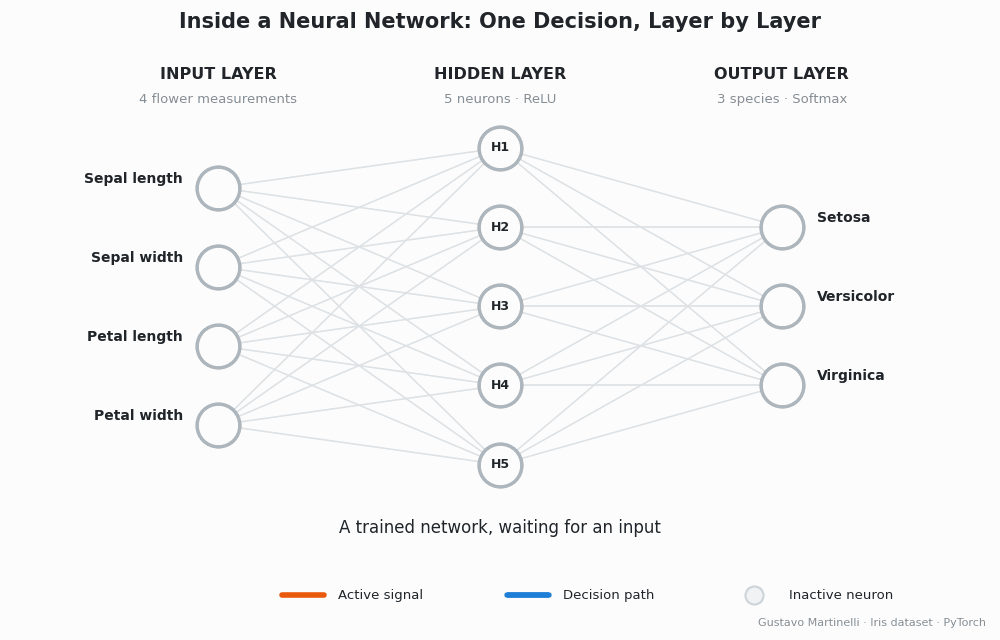

In [12]:
frames, durations = [], []

def add(stage, ms, t=1.0):
    frames.append(draw_frame(stage, t))
    durations.append(ms)

add(0, 1300)                                              # network at rest
add(1, 1600)                                              # inputs light up
for t in np.linspace(0.1, 1, 10): add(2, 60, t)           # signals to hidden layer
add(3, 1800)                                              # ReLU: active / inactive
for t in np.linspace(0.1, 1, 10): add(4, 60, t)           # signals to output layer
add(5, 2000)                                              # probabilities
for t in np.linspace(0.08, 1, 14): add(6, 60, t)          # decision path in blue
add(7, 5000)                                              # final result

GIF_PATH, PNG_PATH = "decision_path.gif", "decision_path_final.png"
# One shared color palette for every frame keeps colors stable (no flicker)
sample = Image.new("RGB", (frames[0].width * 2, frames[0].height))
sample.paste(frames[1], (0, 0))
sample.paste(frames[-1], (frames[0].width, 0))
palette = sample.quantize(colors=128)
palette_frames = [f.quantize(palette=palette, dither=Image.Dither.NONE) for f in frames]
palette_frames[0].save(GIF_PATH, save_all=True, append_images=palette_frames[1:],
                       duration=durations, loop=0, disposal=2)
frames[-1].save(PNG_PATH)

print(f"{len(frames)} frames saved to {GIF_PATH} (final frame also saved to {PNG_PATH})")
display(IPImage(filename=GIF_PATH))

### 7.4 Professional PDF report

This cell turns the explainability report into a **formatted PDF**: a header, identification data, the decision, the main reasons with influence bars, the decision path image and the method and limitations.

It installs one small library (`fpdf2`, a few seconds) and uses the DejaVu font that comes with matplotlib, so special characters such as → display correctly.

> 🏛️ **Governance note:** A decision record that is **formatted, dated and tied to a model version** is easier to file, share with a DPO or attach to a response to the person affected.

In [13]:
%pip install -q fpdf2

import os
from fpdf import FPDF
from fpdf.enums import XPos, YPos

PDF_PATH = "explainability_report.pdf"
FONT_DIR = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")

NAVY, GRAY, DARK = (22, 50, 79), (134, 142, 150), (33, 37, 41)
GREEN, RED = (47, 158, 68), (224, 49, 49)

def rgb(hex_color):
    hex_color = hex_color.lstrip("#")
    return tuple(int(hex_color[i:i + 2], 16) for i in (0, 2, 4))


class ReportPDF(FPDF):
    def footer(self):
        self.set_y(-12)
        self.set_font("DejaVu", "", 7.5)
        self.set_text_color(*GRAY)
        self.cell(0, 5, f"{AUTHOR} · Educational material, not legal advice")
        self.set_x(self.l_margin)
        self.cell(0, 5, f"Page {self.page_no()}/{{nb}}", align="R")


pdf = ReportPDF(format="A4")
pdf.add_font("DejaVu", "", os.path.join(FONT_DIR, "DejaVuSans.ttf"))
pdf.add_font("DejaVu", "B", os.path.join(FONT_DIR, "DejaVuSans-Bold.ttf"))
pdf.set_auto_page_break(True, margin=18)
pdf.add_page()
W = pdf.epw   # usable page width


def section(title):
    pdf.ln(4)
    pdf.set_font("DejaVu", "B", 11.5)
    pdf.set_text_color(*NAVY)
    pdf.cell(0, 7, title, new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_draw_color(222, 226, 230)
    pdf.set_line_width(0.3)
    pdf.line(pdf.l_margin, pdf.get_y(), pdf.l_margin + W, pdf.get_y())
    pdf.ln(2)


def row(label, value, bold=False, color=DARK):
    pdf.set_font("DejaVu", "", 9.5)
    pdf.set_text_color(*GRAY)
    pdf.cell(45, 6, label)
    pdf.set_font("DejaVu", "B" if bold else "", 9.5)
    pdf.set_text_color(*color)
    pdf.cell(0, 6, value, new_x=XPos.LMARGIN, new_y=YPos.NEXT)


# ---- Header band ----
pdf.set_fill_color(*NAVY)
pdf.rect(0, 0, 210, 30, style="F")
pdf.set_fill_color(*rgb(ORANGE))
pdf.rect(0, 30, 210, 1.5, style="F")
pdf.set_xy(pdf.l_margin, 8)
pdf.set_font("DejaVu", "B", 16)
pdf.set_text_color(255, 255, 255)
pdf.cell(0, 8, "Automated Decision · Explainability Report", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_font("DejaVu", "", 9.5)
pdf.set_text_color(200, 215, 230)
pdf.cell(0, 6, f"IrisNet classifier · Test case #{SAMPLE_INDEX} · Generated {now}",
         new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_y(38)

# ---- Decision summary box ----
correct = pred == y_true
box_y = pdf.get_y()
pdf.set_fill_color(241, 243, 245)
pdf.rect(pdf.l_margin, box_y, W, 22, style="F")
pdf.set_fill_color(*rgb(BLUE))
pdf.rect(pdf.l_margin, box_y, 1.5, 22, style="F")
pdf.set_xy(pdf.l_margin + 6, box_y + 3)
pdf.set_font("DejaVu", "", 9)
pdf.set_text_color(*GRAY)
pdf.cell(0, 5, "DECISION", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_x(pdf.l_margin + 6)
pdf.set_font("DejaVu", "B", 15)
pdf.set_text_color(*DARK)
pdf.cell(70, 8, f"{CLASSES[pred]}  ·  {probs[pred]:.1%}")
pdf.set_font("DejaVu", "B", 10)
pdf.set_text_color(*(GREEN if correct else RED))
pdf.cell(0, 8, f"Actual: {CLASSES[y_true]} ({'correct' if correct else 'incorrect'})",
         new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_y(box_y + 22)

# ---- 1. Identification ----
section("1. Identification")
row("Model", f"IrisNet (4-5-3 MLP), {n_params} parameters")
row("Model fingerprint", MODEL_FINGERPRINT, bold=True)
row("Test accuracy", f"{test_acc:.1%}")
row("Case analysed", f"Test sample #{SAMPLE_INDEX}")
row("Alternatives", alternatives)

# ---- 2. Input ----
section("2. Input")
for name, value in zip(FEATURES, x_raw):
    row(name, f"{value:.1f} cm")

# ---- 3. Main reasons ----
section("3. Main reasons (influence on the predicted class)")
pdf.set_font("DejaVu", "", 8.5)
pdf.set_text_color(*GRAY)
pdf.multi_cell(0, 4.5, "Supports = pushed toward this species; opposes = pushed away. "
               "The rest of the decision comes from the model's learned starting point.",
               new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.ln(1.5)
BAR_W = 70
for rank, j in enumerate(ranking):
    supports = feature_influence[j] > 0
    y = pdf.get_y()
    pdf.set_font("DejaVu", "B", 9.5)
    pdf.set_text_color(*DARK)
    pdf.cell(45, 7, f"{rank + 1}. {FEATURES[j]}")
    pdf.set_fill_color(233, 236, 239)
    pdf.rect(pdf.get_x(), y + 2, BAR_W, 3, style="F")
    pdf.set_fill_color(*(GREEN if supports else RED))
    pdf.rect(pdf.get_x(), y + 2, BAR_W * share[j], 3, style="F")
    pdf.set_x(pdf.get_x() + BAR_W + 4)
    pdf.set_font("DejaVu", "", 9.5)
    pdf.cell(15, 7, f"{share[j]:.0%}")
    pdf.set_text_color(*(GREEN if supports else RED))
    pdf.cell(0, 7, "supports" if supports else "opposes", new_x=XPos.LMARGIN, new_y=YPos.NEXT)

# ---- 4. Internal decision path ----
IMG_W = 150   # image width in mm, centered
img_px_w, img_px_h = Image.open(PNG_PATH).size
needed = IMG_W * img_px_h / img_px_w + 30   # image + heading + two rows
if pdf.get_y() + needed > pdf.h - 18:      # keep the section together
    pdf.add_page()
section("4. Internal decision path")
row("Dominant route", f"{FEATURES[PATH[0]]} → H{PATH[1] + 1} → {CLASSES[PATH[2]]}",
    bold=True, color=rgb(BLUE))
row("Inactive neurons", ", ".join(inactive) or "none")
pdf.ln(2)
pdf.image(PNG_PATH, x=pdf.l_margin + (W - IMG_W) / 2, w=IMG_W)

# ---- 5. Method and limitations ----
section("5. Method and limitations")
pdf.set_font("DejaVu", "", 9)
pdf.set_text_color(*DARK)
for item in [
    "Influence = exact gradient × input decomposition for this input, measured relative "
    "to the average flower in the training data.",
    "The decision path highlights the strongest route; every active neuron contributes "
    "to the final result.",
    "This report explains one decision only, not the model's overall behaviour.",
    "Human review is recommended before relying on this decision.",
]:
    pdf.multi_cell(0, 5, f"•  {item}", align="L", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(0.5)

pdf.output(PDF_PATH)
print(f"PDF report saved to {PDF_PATH} ({pdf.pages_count} pages)")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.3/341.3 kB 13.0 MB/s eta 0:00:00
PDF report saved to explainability_report.pdf (2 pages)


### 7.5 Downloading the results

This cell downloads the four outputs to your computer:

- `decision_path.gif`: the animation for the post
- `decision_path_final.png`: the static final frame
- `explainability_report.pdf`: the professional report
- `explainability_report.txt`: the plain-text version of the report

*If your browser blocks multiple downloads, allow them for colab.research.google.com, or use the 📁 Files panel on the left.*

In [14]:
OUTPUTS = [GIF_PATH, PNG_PATH, PDF_PATH, "explainability_report.txt"]

try:
    from google.colab import files
    for path in OUTPUTS:
        files.download(path)
except ImportError:
    print("Not running in Colab. The files are saved in the current folder:")
    for path in OUTPUTS:
        print(f"  - {path}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. 🎯 Key Takeaways

1. **Small models can be explained exactly.** With 43 parameters, we traced every signal from input to decision.
2. **Not every neuron participates.** ReLU switched some neurons off for this input, so different inputs use different parts of the network.
3. **Explanations are local.** This report explains *one* decision. Another flower could follow a completely different route.
4. **Explanations need context to be trustworthy:** a model version (fingerprint), a baseline (the average flower), a method and its stated limitations.
5. **Explainability is a communication task.** The same decision was described as numbers (Section 5), as a report (Section 6) and as an animation (Section 7), one form for each audience.

## 9. ⚠️ Limitations

- **The decision path is a simplification.** In a dense network, every active neuron contributes; the blue route shows only the strongest one.
- **Gradient × input is a local, first-order method.** For production systems, more robust methods such as **SHAP** or **Integrated Gradients** are recommended, ideally combined.
- **This does not scale visually.** Large models, such as language models with billions of parameters, cannot be drawn neuron by neuron. They require aggregated techniques like feature attribution, probing and mechanistic interpretability.
- **Technical explanation ≠ legal compliance.** Regulations also require documentation, risk management, human oversight and processes to contest decisions.

> *This notebook is for educational purposes and does not constitute legal advice.*

## 10. 🚀 Going Further

### 10.1 Experiments to try in this notebook
- Change `SAMPLE_INDEX` in Section 5.1 and compare decision paths across flowers.
- Increase the hidden layer (for example `nn.Linear(4, 8)`) and see how the explanation changes.
- Pick a flower the model got **wrong** and read its report. What would an auditor ask?

### 10.2 Tools for real-world explainability
- **[SHAP](https://shap.readthedocs.io/)**: model-agnostic feature attribution based on Shapley values.
- **[Captum](https://captum.ai/)**: PyTorch's interpretability library (Integrated Gradients, DeepLIFT and more).
- **Model Cards** and **Datasheets for Datasets**: structured documentation for models and data.

### 10.3 Governance frameworks
- **ISO/IEC 42001**: AI management systems
- **ISO/IEC 23894**: AI risk management
- **NIST AI RMF**: names *explainable and interpretable* as a trustworthiness characteristic

## 📚 References

| Reference | Topic |
|---|---|
| [LGPD, Lei nº 13.709/2018, Art. 20](https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm) | Review of automated decisions; information on criteria and procedures |
| [EU AI Act, Regulation (EU) 2024/1689, Arts. 13 and 86](https://eur-lex.europa.eu/eli/reg/2024/1689/oj) | Transparency; right to explanation of individual decisions |
| [GDPR, Regulation (EU) 2016/679, Art. 22](https://eur-lex.europa.eu/eli/reg/2016/679/oj) | Automated individual decision-making |
| [ISO/IEC 42001:2023](https://www.iso.org/standard/81230.html) | AI management system |
| [NIST AI Risk Management Framework](https://www.nist.gov/itl/ai-risk-management-framework) | Trustworthy AI characteristics |
| [Iris dataset, UCI Repository](https://archive.ics.uci.edu/dataset/53/iris) | R. A. Fisher (1936) |
| [PyTorch forward hooks](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook) | Recording internal activations |

## 🤝 Let's Connect

Thank you for exploring this notebook! 🙏

If it was useful, I'd love to hear your thoughts. **Which automated decisions in your organization should come with an explanation like this?**

⭐ **Enjoyed it?** [Star the repository](https://github.com/gustavomartinellidev/ai-governance-lab) and follow me for the next notebooks.

<a href="https://www.linkedin.com/in/gustavomartinelli/" target="_blank">🔗 <b>Gustavo Martinelli</b> on LinkedIn</a>

*Feel free to copy, adapt and share this notebook, with attribution.*